In [23]:
import pandas as pd
import matplotlib.pyplot as plt
sayisal = ["tenure", "MonthlyCharges", "TotalCharges"]

df = pd.read_csv("../../data/processed/temiz_veri.csv")
df.info()
print(df["Churn"].value_counts()) #csv dosyası eksiksiz yğklenmiş mi churn değerlerine bakarak kontrol ediyoruz

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

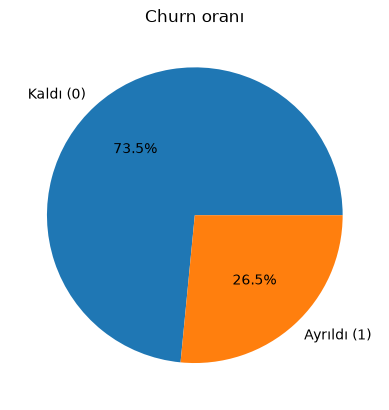

In [17]:
# Ayrılan ve kalan müşteri oranı (sampling notu: veri dengesiz, yaklaşık %26 / %74).
churn_sayi = df["Churn"].value_counts()

plt.pie(churn_sayi, labels=["Kaldı (0)", "Ayrıldı (1)"], autopct="%1.1f%%")
plt.title("Churn oranı")
plt.show()

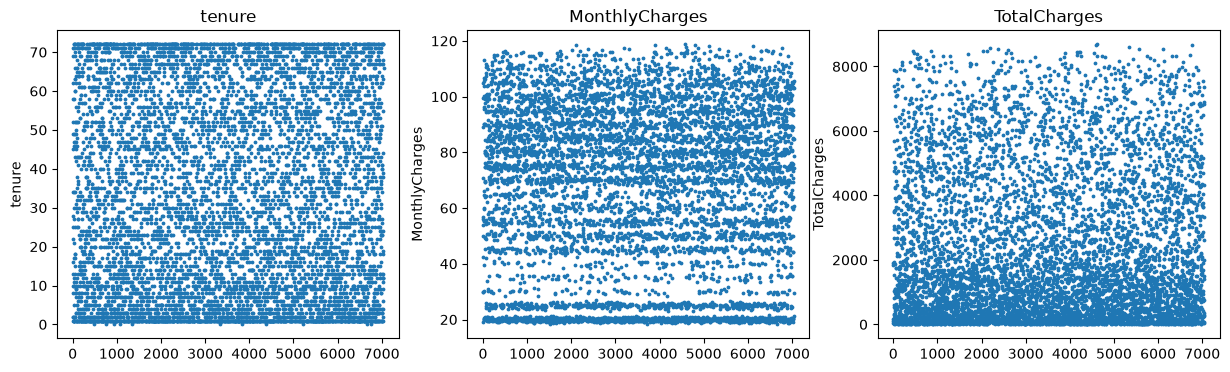

In [18]:
# Her sayısal sütunun kendi noktasal dağılımı 
# Yatay eksen: müşteri sırası(verisetindeki satır sayısı), dikey eksen: sütunun değeri.

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(sayisal):
    ax[i].scatter(df.index, df[col], s=3)
    ax[i].set_title(col)
    ax[i].set_ylabel(col)

plt.show()

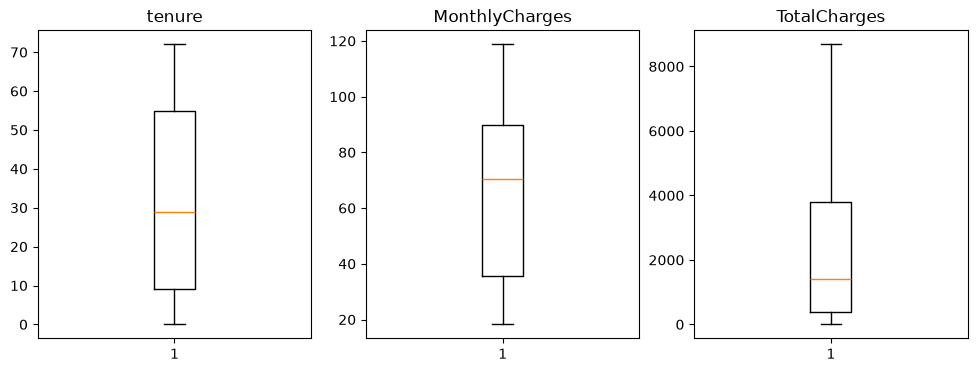

In [19]:
# Outlier (ıpr yöntemiyle) kontrolü her sayısal sütun için ayrı boxplot.
# Bıyıkların dışında kalan noktalar outlier adayıdır.
#turuncu çizgi medyan, kutu verinin ortadaki yarısı 
#dışarıda bir nokta varsa o outlierdır
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

for i, col in enumerate(sayisal):
    ax[i].boxplot(df[col])
    ax[i].set_title(col)

plt.show()

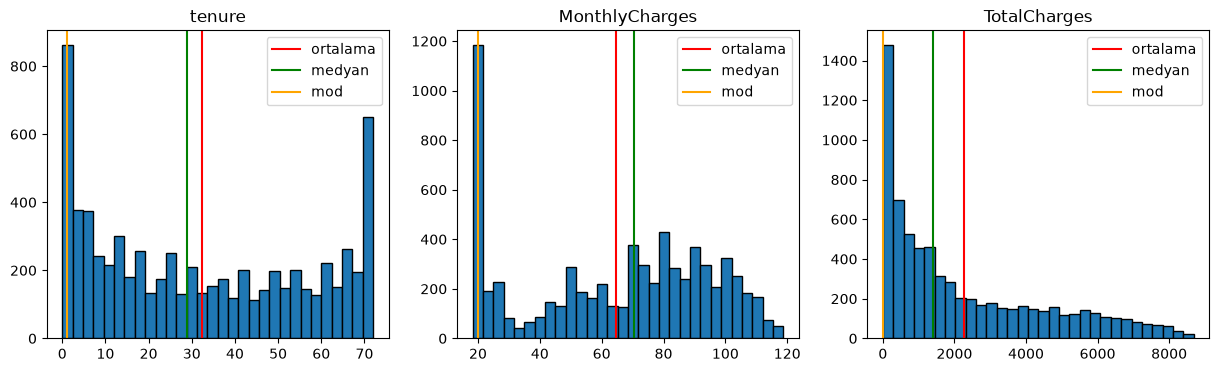

In [20]:
# Her sayısal sütunun dağılımını histogramla çiziyoruz.
# Krmızı çizgi: ortalama, yeşil çizgi: medyan.
# kisi yakınsa dağılım simetrik, uzaksa bir yana yatık (çarpık).
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

for i, col in enumerate(sayisal):
    ax[i].hist(df[col], bins=30, edgecolor="black")
    ax[i].axvline(df[col].mean(), color="red", label="ortalama")
    ax[i].axvline(df[col].median(), color="green", label="medyan")
    ax[i].axvline(df[col].mode()[0], color="orange", label="mod")
    ax[i].set_title(col)
    ax[i].legend()

plt.show()

In [21]:
# moments grafikleri 
print("ORTALAMA\n", df[sayisal].mean(), "\n")#mean (ortalama)
print("MEDYAN\n", df[sayisal].median(), "\n")#medyan 8sıralanınca ortadaki değer=)
print("MOD\n", df[sayisal].mode().iloc[0], "\n")#her sütunun modunu ( en çok tekrar eden değerini verir)
print("VARYANS\n", df[sayisal].var(), "\n")#varyans(ortalanadan yayılma)
print("STANDART SAPMA\n", df[sayisal].std(), "\n")#standart sapma (varyansın karekökü, sütunun kendi biriminde yayılma)
print("SKEWNESS (çarpıklık)\n", df[sayisal].skew(), "\n")#skewness grafiği
print("KURTOSIS (basıklık)\n", df[sayisal].kurt())#kurtosis
print(df[sayisal + ["Churn"]].cov())#kovaryans 

ORTALAMA
 tenure              32.371149
MonthlyCharges      64.761692
TotalCharges      2279.734304
dtype: float64 

MEDYAN
 tenure              29.00
MonthlyCharges      70.35
TotalCharges      1394.55
dtype: float64 

MOD
 tenure             1.00
MonthlyCharges    20.05
TotalCharges       0.00
Name: 0, dtype: float64 

VARYANS
 tenure            6.031681e+02
MonthlyCharges    9.054109e+02
TotalCharges      5.138357e+06
dtype: float64 

STANDART SAPMA
 tenure              24.559481
MonthlyCharges      30.090047
TotalCharges      2266.794470
dtype: float64 

SKEWNESS (çarpıklık)
 tenure            0.239540
MonthlyCharges   -0.220524
TotalCharges      0.963235
dtype: float64 

KURTOSIS (basıklık)
 tenure           -1.387372
MonthlyCharges   -1.257260
TotalCharges     -0.228580
dtype: float64
                      tenure  MonthlyCharges  TotalCharges       Churn
tenure            603.168108      183.196987  4.599442e+04   -3.819750
MonthlyCharges    183.196987      905.410934  4.441523e+

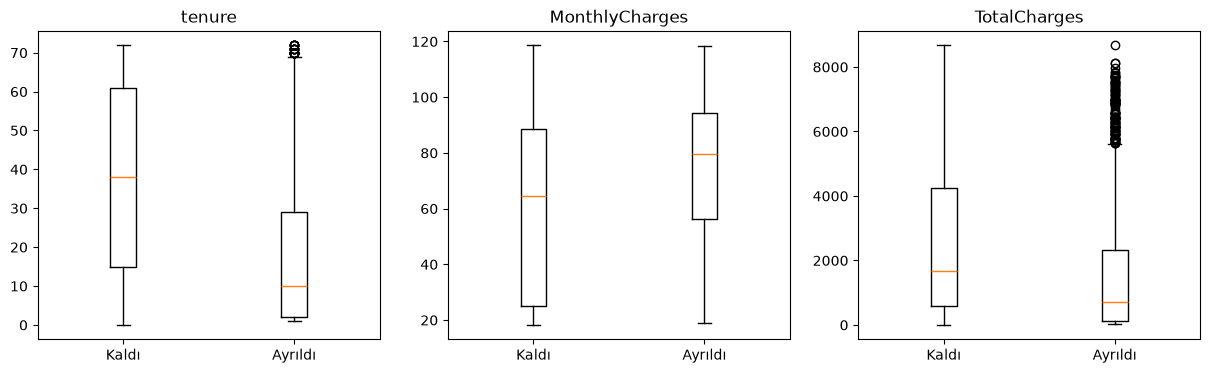

In [22]:
# Sayısal sütunlarda ayrılanlar ile kalanların karşılaştırması.
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(sayisal):
    ax[i].boxplot([df[df["Churn"] == 0][col], df[df["Churn"] == 1][col]],
                  tick_labels=["Kaldı", "Ayrıldı"])
    ax[i].set_title(col)
plt.show()